# Q-SHIELD-PQC: Quantum-Safe Hybrid Key Exchange & Universal Processor A/B Benchmarking
**Qiskit Fall Fest 2026 (SRM University-AP) — Track 5: Post-Quantum Cryptography**
**Problem Statement PS-P1 (Primary Submission Statement)**

This notebook executes an end-to-end, fully reproducible empirical evaluation of:
1. **PS-P1 Hybrid Key Exchange**: Classical ECDH (NIST P-256) combined with NIST FIPS 203 ML-KEM-768 via transcript-bound HKDF-SHA256.
2. **Platform A vs Platform B Evaluation**: Benchmarking handshake latency, wire sizes, and memory overhead across unconstrained multi-core and constrained (single-core affinity core 0) CPU environments.
3. **Universal Processor A/B Framework**: Qiskit Aer circuit transpilation, routing overhead (depth, CX, estimated SWAP), and noisy execution fidelity comparing 5-qubit linear chain (Processor A) vs 9-qubit sparse heavy-hex (Processor B).
4. **Mandated Results Generation**: Generates comparison tables in `results/tables/` and publication figures in `results/figures/`.


In [1]:
import sys
from pathlib import Path

# Ensure project root is on sys.path
root_dir = Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

import src
import src.problem as problem
import src.processors as processors
import src.routing as routing
import src.metrics as metrics
import src.visualization as visualization
import pandas as pd
from IPython.display import display, Image

print(f"Q-SHIELD-PQC src modules successfully loaded.")
print(f"Track: {src.__track__}")
print(f"Selected Problem Statement: {src.__problem_statement__}")


Q-SHIELD-PQC src modules successfully loaded.
Track: Track 5: Post-Quantum Cryptography & Quantum-Safe Systems
Selected Problem Statement: PS-P1: Quantum-Safe Hybrid Key Exchange


## 1. Single-Session Ephemeral Hybrid Key Exchange
We execute an end-to-end Alice (Initiator) <-> Bob (Responder) handshake. Both parties exchange ephemeral public keys, encapsulate/decapsulate, and derive a 256-bit symmetric master key bound to the full SHA-256 transcript hash.


In [2]:
exchange_result = problem.run_hybrid_handshake("Reproducible Jupyter execution message.")

print("=== HYBRID HANDSHAKE VERIFICATION ===")
print("Success:", exchange_result["success"])
print("ECDH Secrets Match:", exchange_result["verification"]["ecdh_secrets_match"])
print("ML-KEM Secrets Match:", exchange_result["verification"]["mlkem_secrets_match"])
print("Hybrid Derived Keys Match:", exchange_result["verification"]["hybrid_keys_match"])
print("Alice Key Fingerprint (SHA-256):", exchange_result["verification"]["alice_key_fingerprint_sha256"])
print("Bob Key Fingerprint (SHA-256):  ", exchange_result["verification"]["bob_key_fingerprint_sha256"])
print(f"Total Handshake Latency: {exchange_result['timings_ms']['total_handshake_ms']:.3f} ms")
print(f"Total Wire Payload: {exchange_result['payload_sizes']['total_exchange_payload_bytes']} bytes")


=== HYBRID HANDSHAKE VERIFICATION ===
Success: True
ECDH Secrets Match: True
ML-KEM Secrets Match: True
Hybrid Derived Keys Match: True
Alice Key Fingerprint (SHA-256): f752de41185f2653917a8fa079c985bac50d79d67262fb76007f35e26ba4c991
Bob Key Fingerprint (SHA-256):   f752de41185f2653917a8fa079c985bac50d79d67262fb76007f35e26ba4c991
Total Handshake Latency: 14.604 ms
Total Wire Payload: 2402 bytes


## 2. Platform A vs Platform B Empirical Benchmark
We run 50 measured trials (+5 warmup) across both CPU execution profiles:
- **Platform A**: Standard multi-core workstation CPU with dynamic OS scheduling.
- **Platform B**: Single-core CPU affinity (Process locked to Core 0) with serialized execution.


In [3]:
print("Executing dual-platform benchmark (50 trials per profile)...")
crypto_results = problem.run_crypto_benchmark(
    iterations=50,
    platform_profile="both",
    warmup_iterations=5,
    benchmark_mode="hybrid",
    save_csv=True
)

res_a = crypto_results["platform_a_result"]
res_b = crypto_results["platform_b_result"]

mean_a = res_a["statistics"]["total_handshake_ms"]["mean_ms"]
p95_a = res_a["statistics"]["total_handshake_ms"]["p95_ms"]
mean_b = res_b["statistics"]["total_handshake_ms"]["mean_ms"]
p95_b = res_b["statistics"]["total_handshake_ms"]["p95_ms"]

print(f"Platform A Mean Handshake: {mean_a:.3f} ms (p95: {p95_a:.3f} ms)")
print(f"Platform B Mean Handshake: {mean_b:.3f} ms (p95: {p95_b:.3f} ms)")
overhead_pct = crypto_results["comparison_summary"]["relative_latency_overhead_percent"]
print(f"Platform B Relative Latency Overhead: {overhead_pct:.1f}%")


Executing dual-platform benchmark (50 trials per profile)...


Platform A Mean Handshake: 1.251 ms (p95: 1.858 ms)
Platform B Mean Handshake: 1.602 ms (p95: 2.023 ms)
Platform B Relative Latency Overhead: 28.0%


## 3. Universal Processor A/B Quantum Architecture Simulation
We evaluate circuit transpilation overhead, routing constraints, and noisy simulation fidelity in Qiskit Aer between:
- **Processor A**: 5 qubits, baseline linear chain `[(0,1),(1,2),(2,3),(3,4)]`
- **Processor B**: 9 qubits, reference sparse heavy-hex `[(0,1),(1,2),(1,6),(2,3),(2,6),(2,5),(3,4),(4,5),(5,6),(6,7),(6,8),(8,0)]`
Under identical synthetic noise (1q depol 0.001, 2q CX 0.005, readout error 0.01) and baseline transpiler settings (`opt_level=1`, `seed=42`, `shots=4096`).


In [4]:
proc_benchmark = routing.run_processor_ab_benchmark(
    circuit_id="qft_5",
    shots=4096,
    optimization_level=1,
    seed=42,
    save_csv=True
)

depth_a = proc_benchmark["processor_a"]["metrics"]["transpiled_depth"]
cx_a = proc_benchmark["processor_a"]["metrics"]["transpiled_cx_count"]
swap_a = proc_benchmark["processor_a"]["metrics"]["swap_gate_estimate"]
fid_a = proc_benchmark["processor_a"]["hellinger_fidelity"]

depth_b = proc_benchmark["processor_b"]["metrics"]["transpiled_depth"]
cx_b = proc_benchmark["processor_b"]["metrics"]["transpiled_cx_count"]
swap_b = proc_benchmark["processor_b"]["metrics"]["swap_gate_estimate"]
fid_b = proc_benchmark["processor_b"]["hellinger_fidelity"]

print("=== QUANTUM ARCHITECTURAL BENCHMARK RESULTS (QFT-5) ===")
print("Logical Depth:", proc_benchmark["circuit"]["logical_depth"])
print(f"Processor A (5Q Linear) Depth: {depth_a} | CX: {cx_a} | SWAP est: {swap_a} | Fidelity: {fid_a}")
print(f"Processor B (9Q Heavy-Hex) Depth: {depth_b} | CX: {cx_b} | SWAP est: {swap_b} | Fidelity: {fid_b}")
print(f"CX Reduction on Processor B: {proc_benchmark['comparison_summary']['cx_reduction_b_vs_a_percent']}%")
print(f"Depth Reduction on Processor B: {proc_benchmark['comparison_summary']['depth_reduction_b_vs_a_percent']}%")


=== QUANTUM ARCHITECTURAL BENCHMARK RESULTS (QFT-5) ===
Logical Depth: 17
Processor A (5Q Linear) Depth: 77 | CX: 50 | SWAP est: 16.67 | Fidelity: 0.9998
Processor B (9Q Heavy-Hex) Depth: 63 | CX: 32 | SWAP est: 10.67 | Fidelity: 0.9999
CX Reduction on Processor B: 36.0%
Depth Reduction on Processor B: 18.18%


## 4. Mandated Results Figures & Tables Generation
Generating publication figures into `results/figures/` and summary tables into `results/tables/`.


In [5]:
fig_latency = visualization.plot_handshake_latency(res_a["statistics"], res_b["statistics"])
fig_sizes = visualization.plot_message_sizes()
fig_mem = visualization.plot_memory_overhead(res_a["memory_overhead"], res_b["memory_overhead"])
fig_proc = visualization.plot_processor_comparison(proc_benchmark)
fig_topos = visualization.plot_coupling_topologies()

print("Figures successfully generated:")
print("1.", fig_latency)
print("2.", fig_sizes)
print("3.", fig_mem)
print("4.", fig_proc)
print("5.", fig_topos)


Figures successfully generated:
1. C:\Users\LUMBINI DEVI\Desktop\qff26\results\figures\crypto_latency_breakdown.png
2. C:\Users\LUMBINI DEVI\Desktop\qff26\results\figures\crypto_message_sizes.png
3. C:\Users\LUMBINI DEVI\Desktop\qff26\results\figures\crypto_memory_overhead.png
4. C:\Users\LUMBINI DEVI\Desktop\qff26\results\figures\processor_ab_comparison.png
5. C:\Users\LUMBINI DEVI\Desktop\qff26\results\figures\processor_coupling_maps.png


### Figure 1: Handshake Latency Comparison (Platform A vs B)

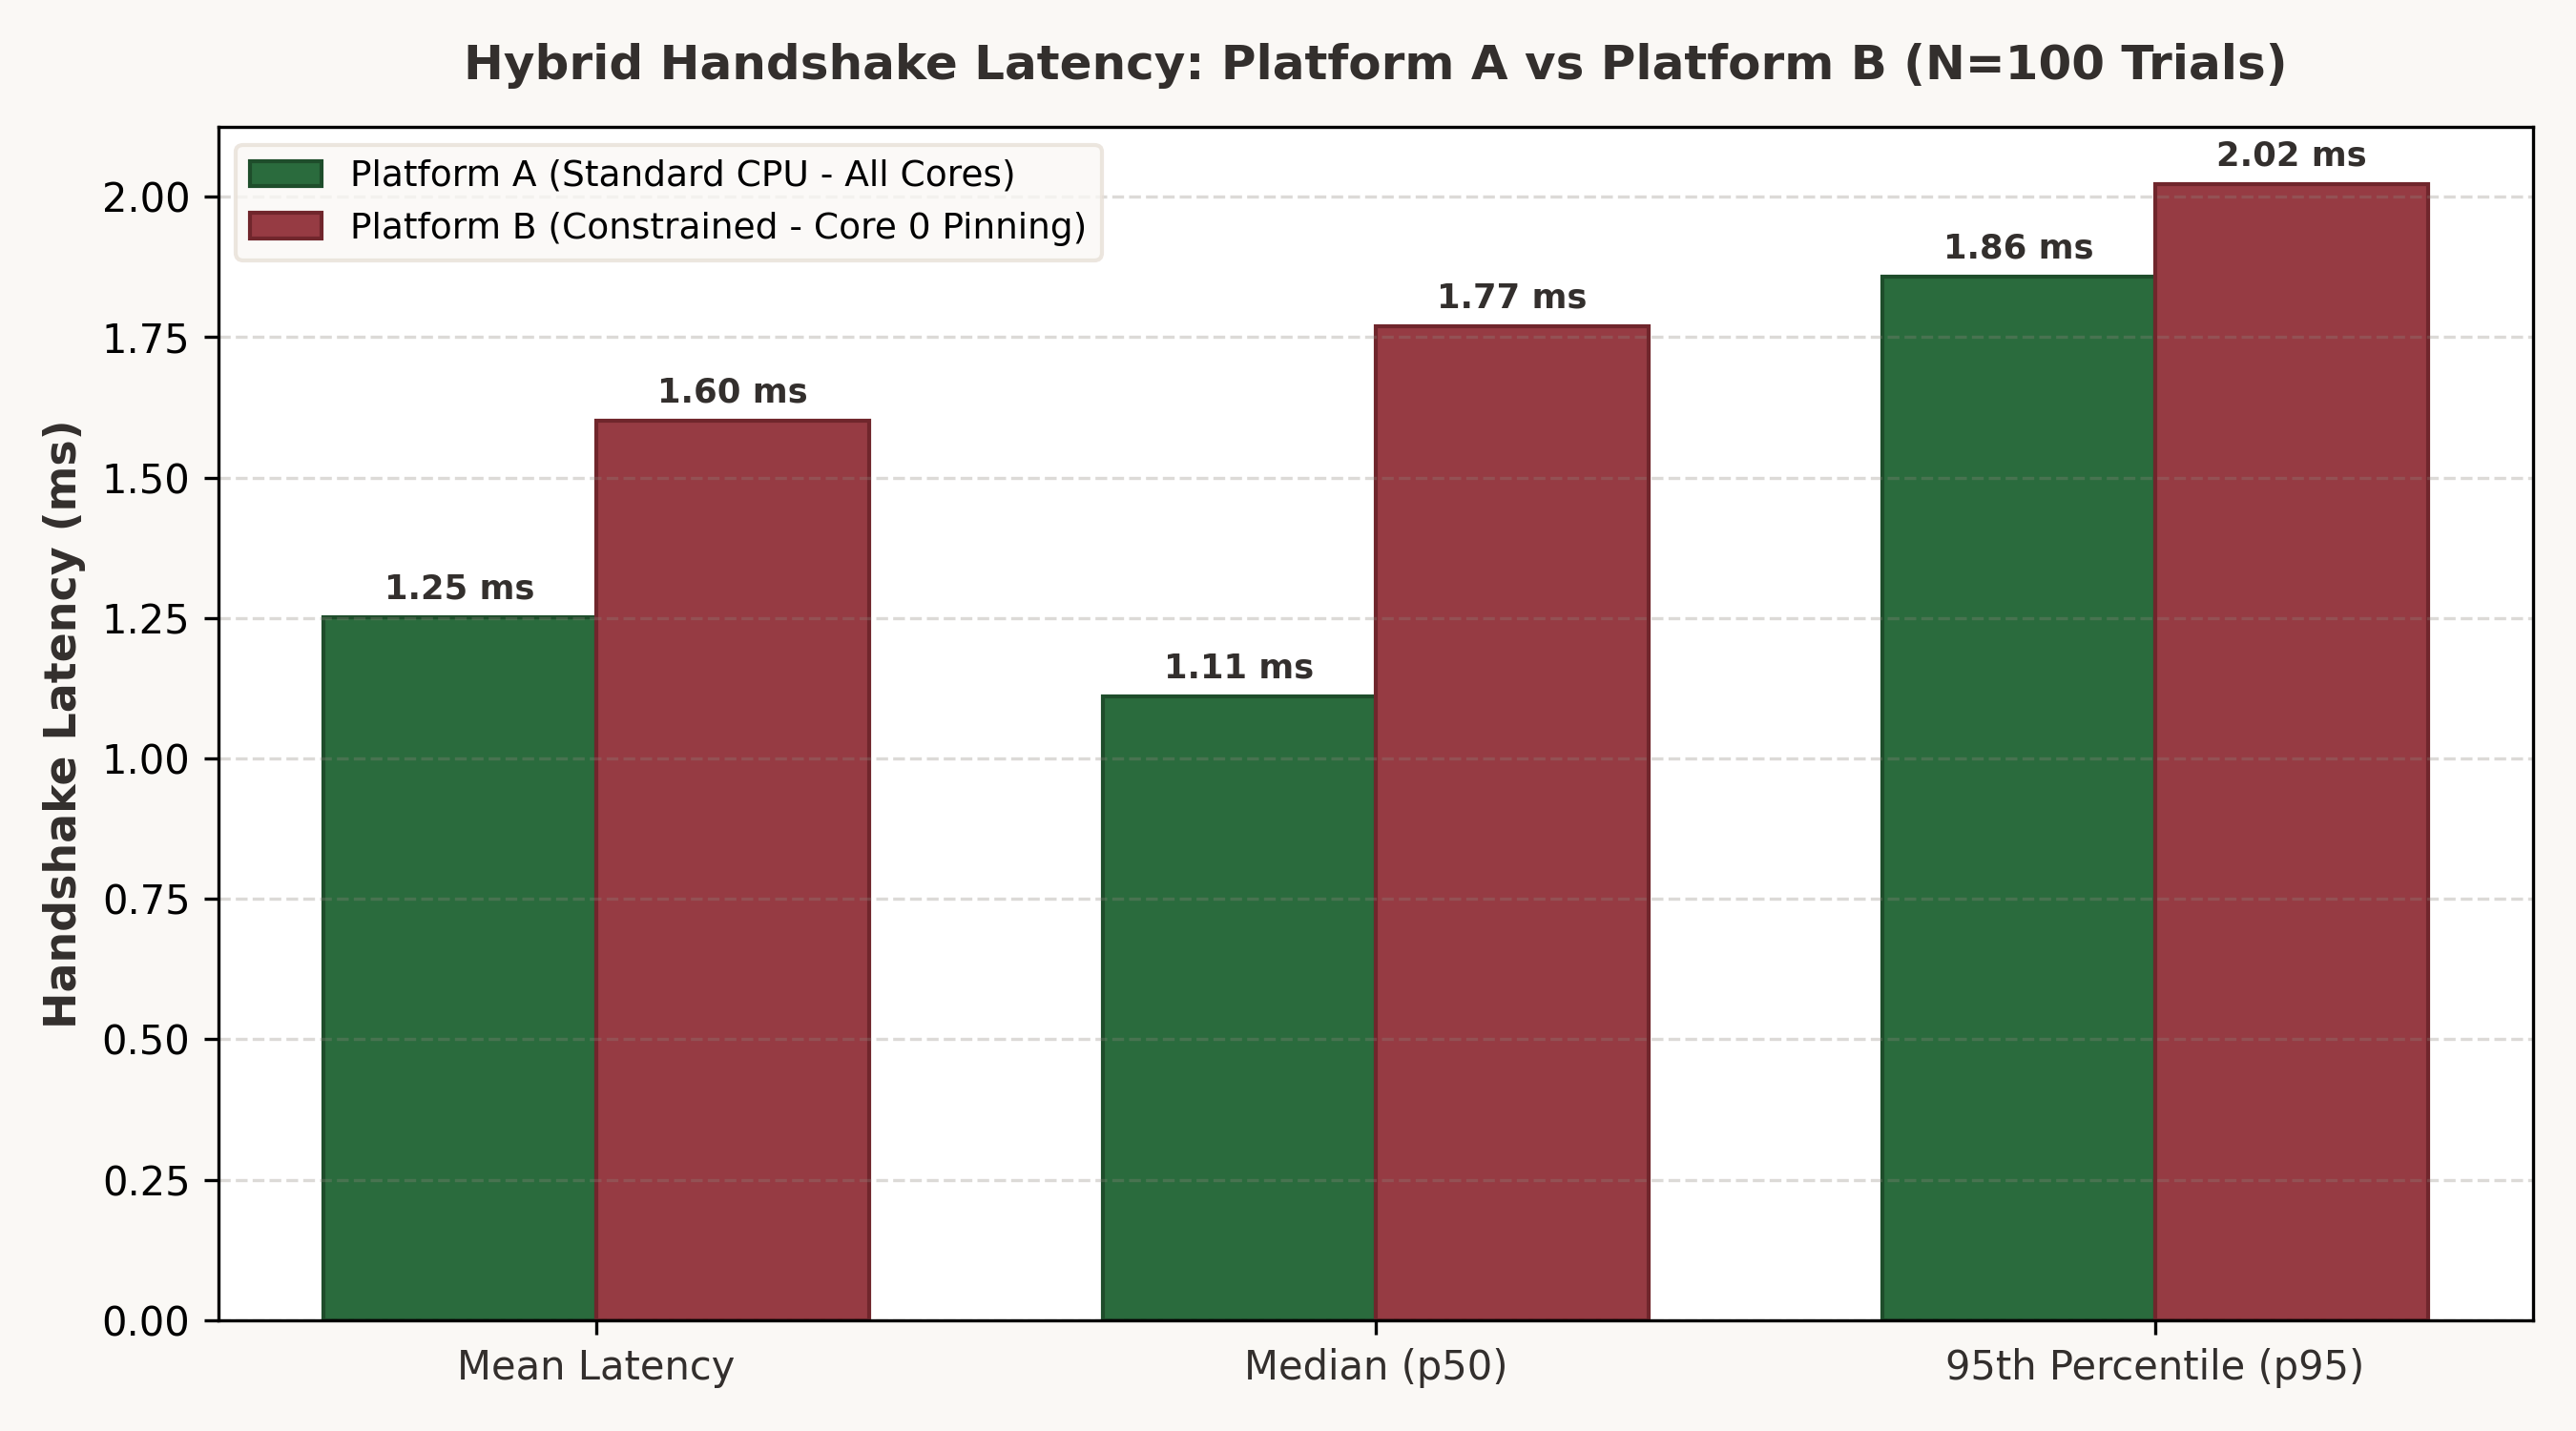

In [6]:
display(Image(filename=fig_latency))

### Figure 2: Cryptographic Wire Payload Breakdown

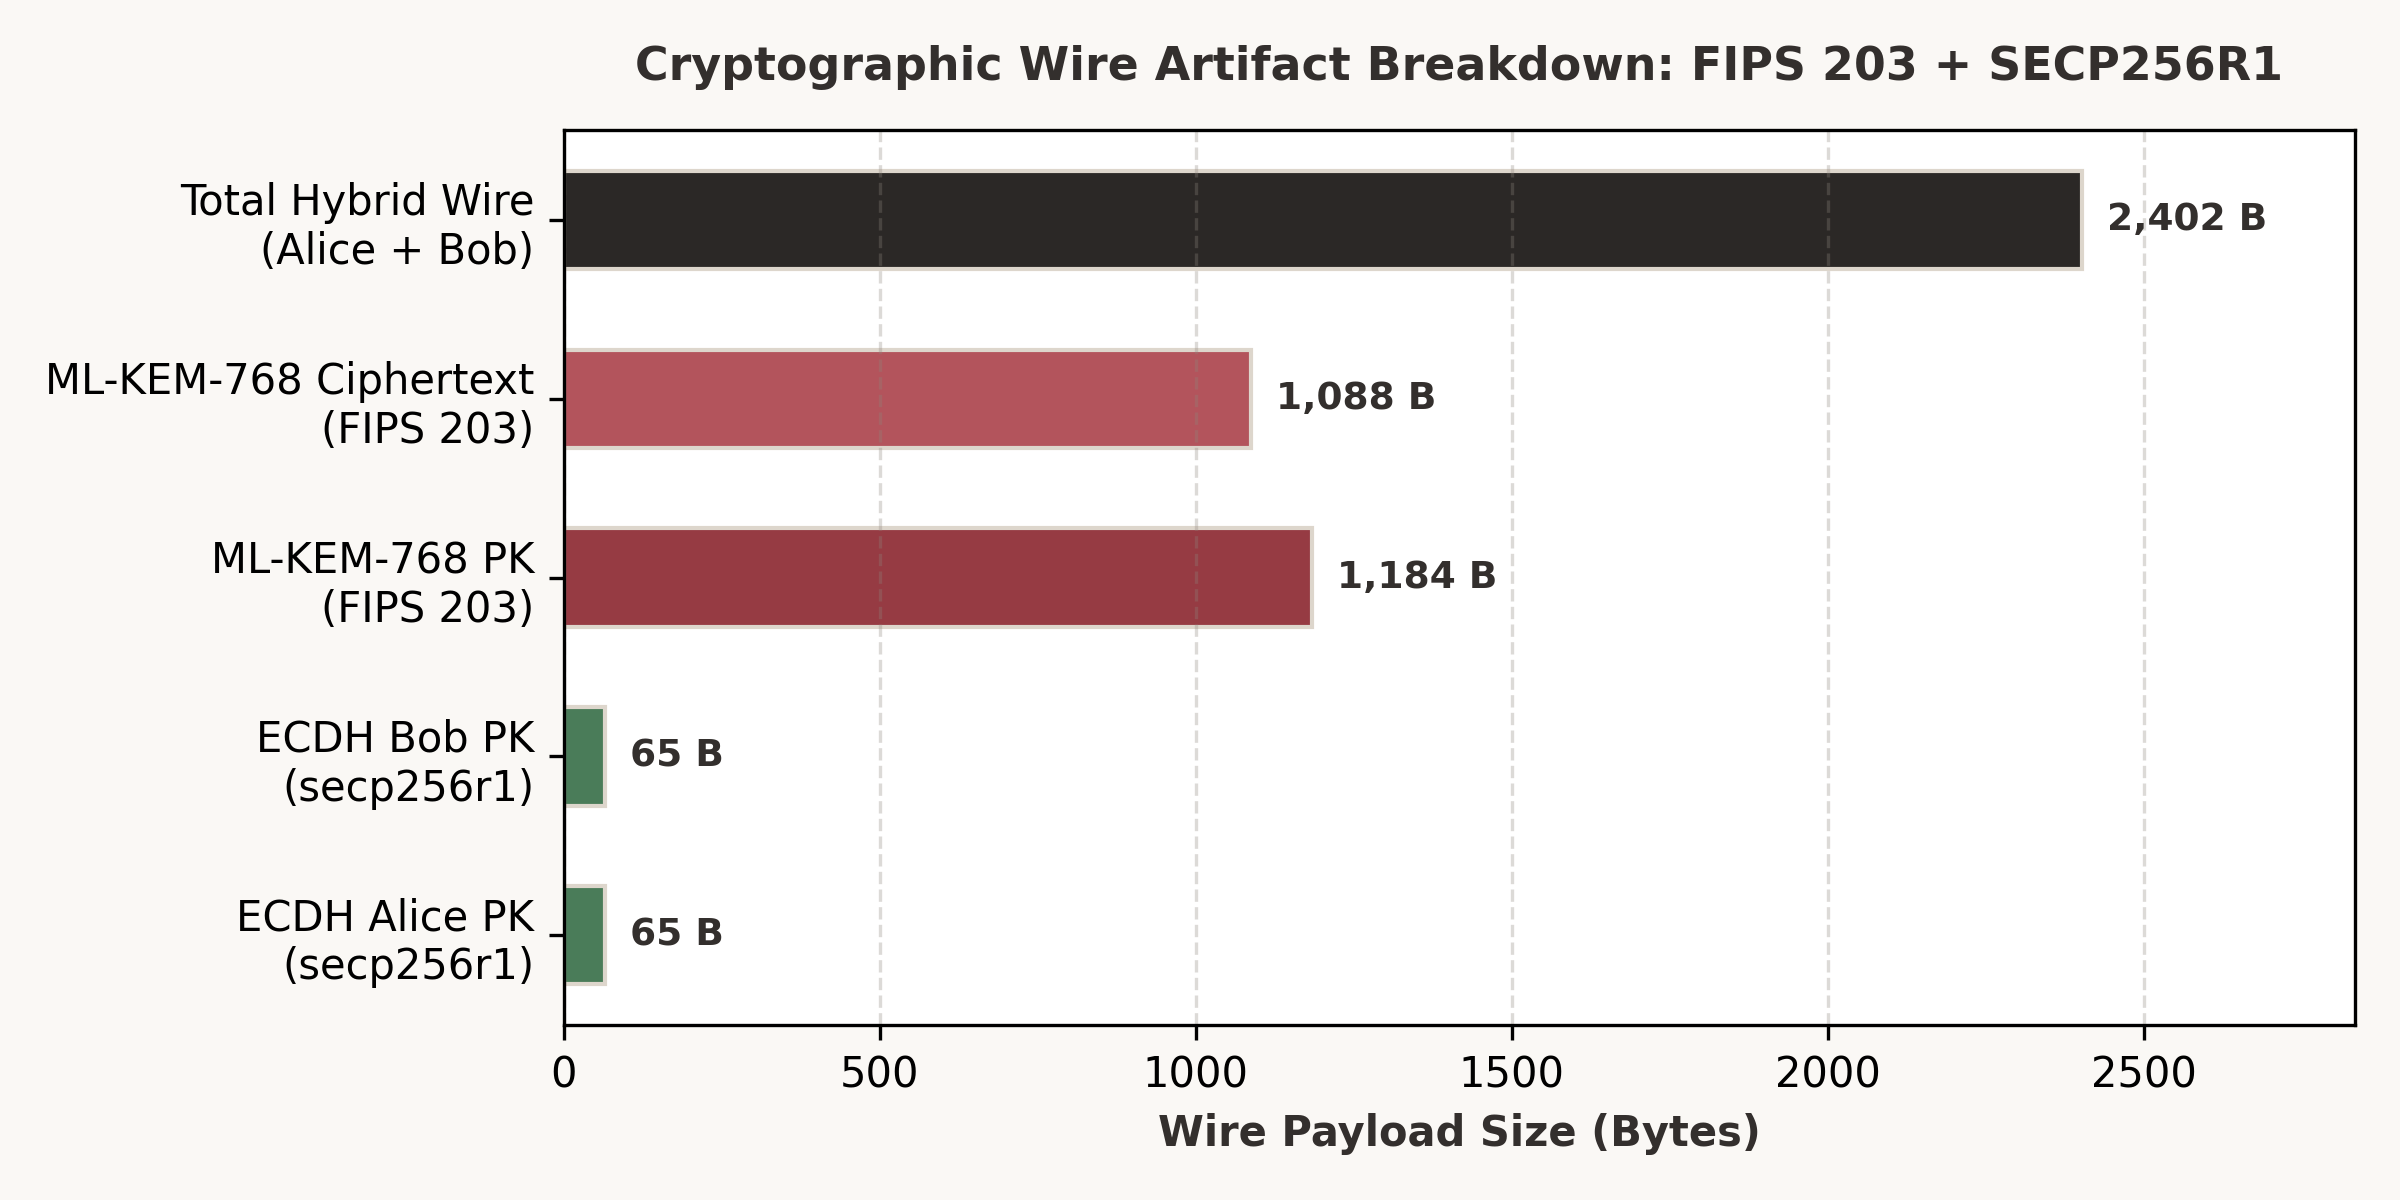

In [7]:
display(Image(filename=fig_sizes))

### Figure 3: Memory Overhead (Python Heap vs OS Process RSS)

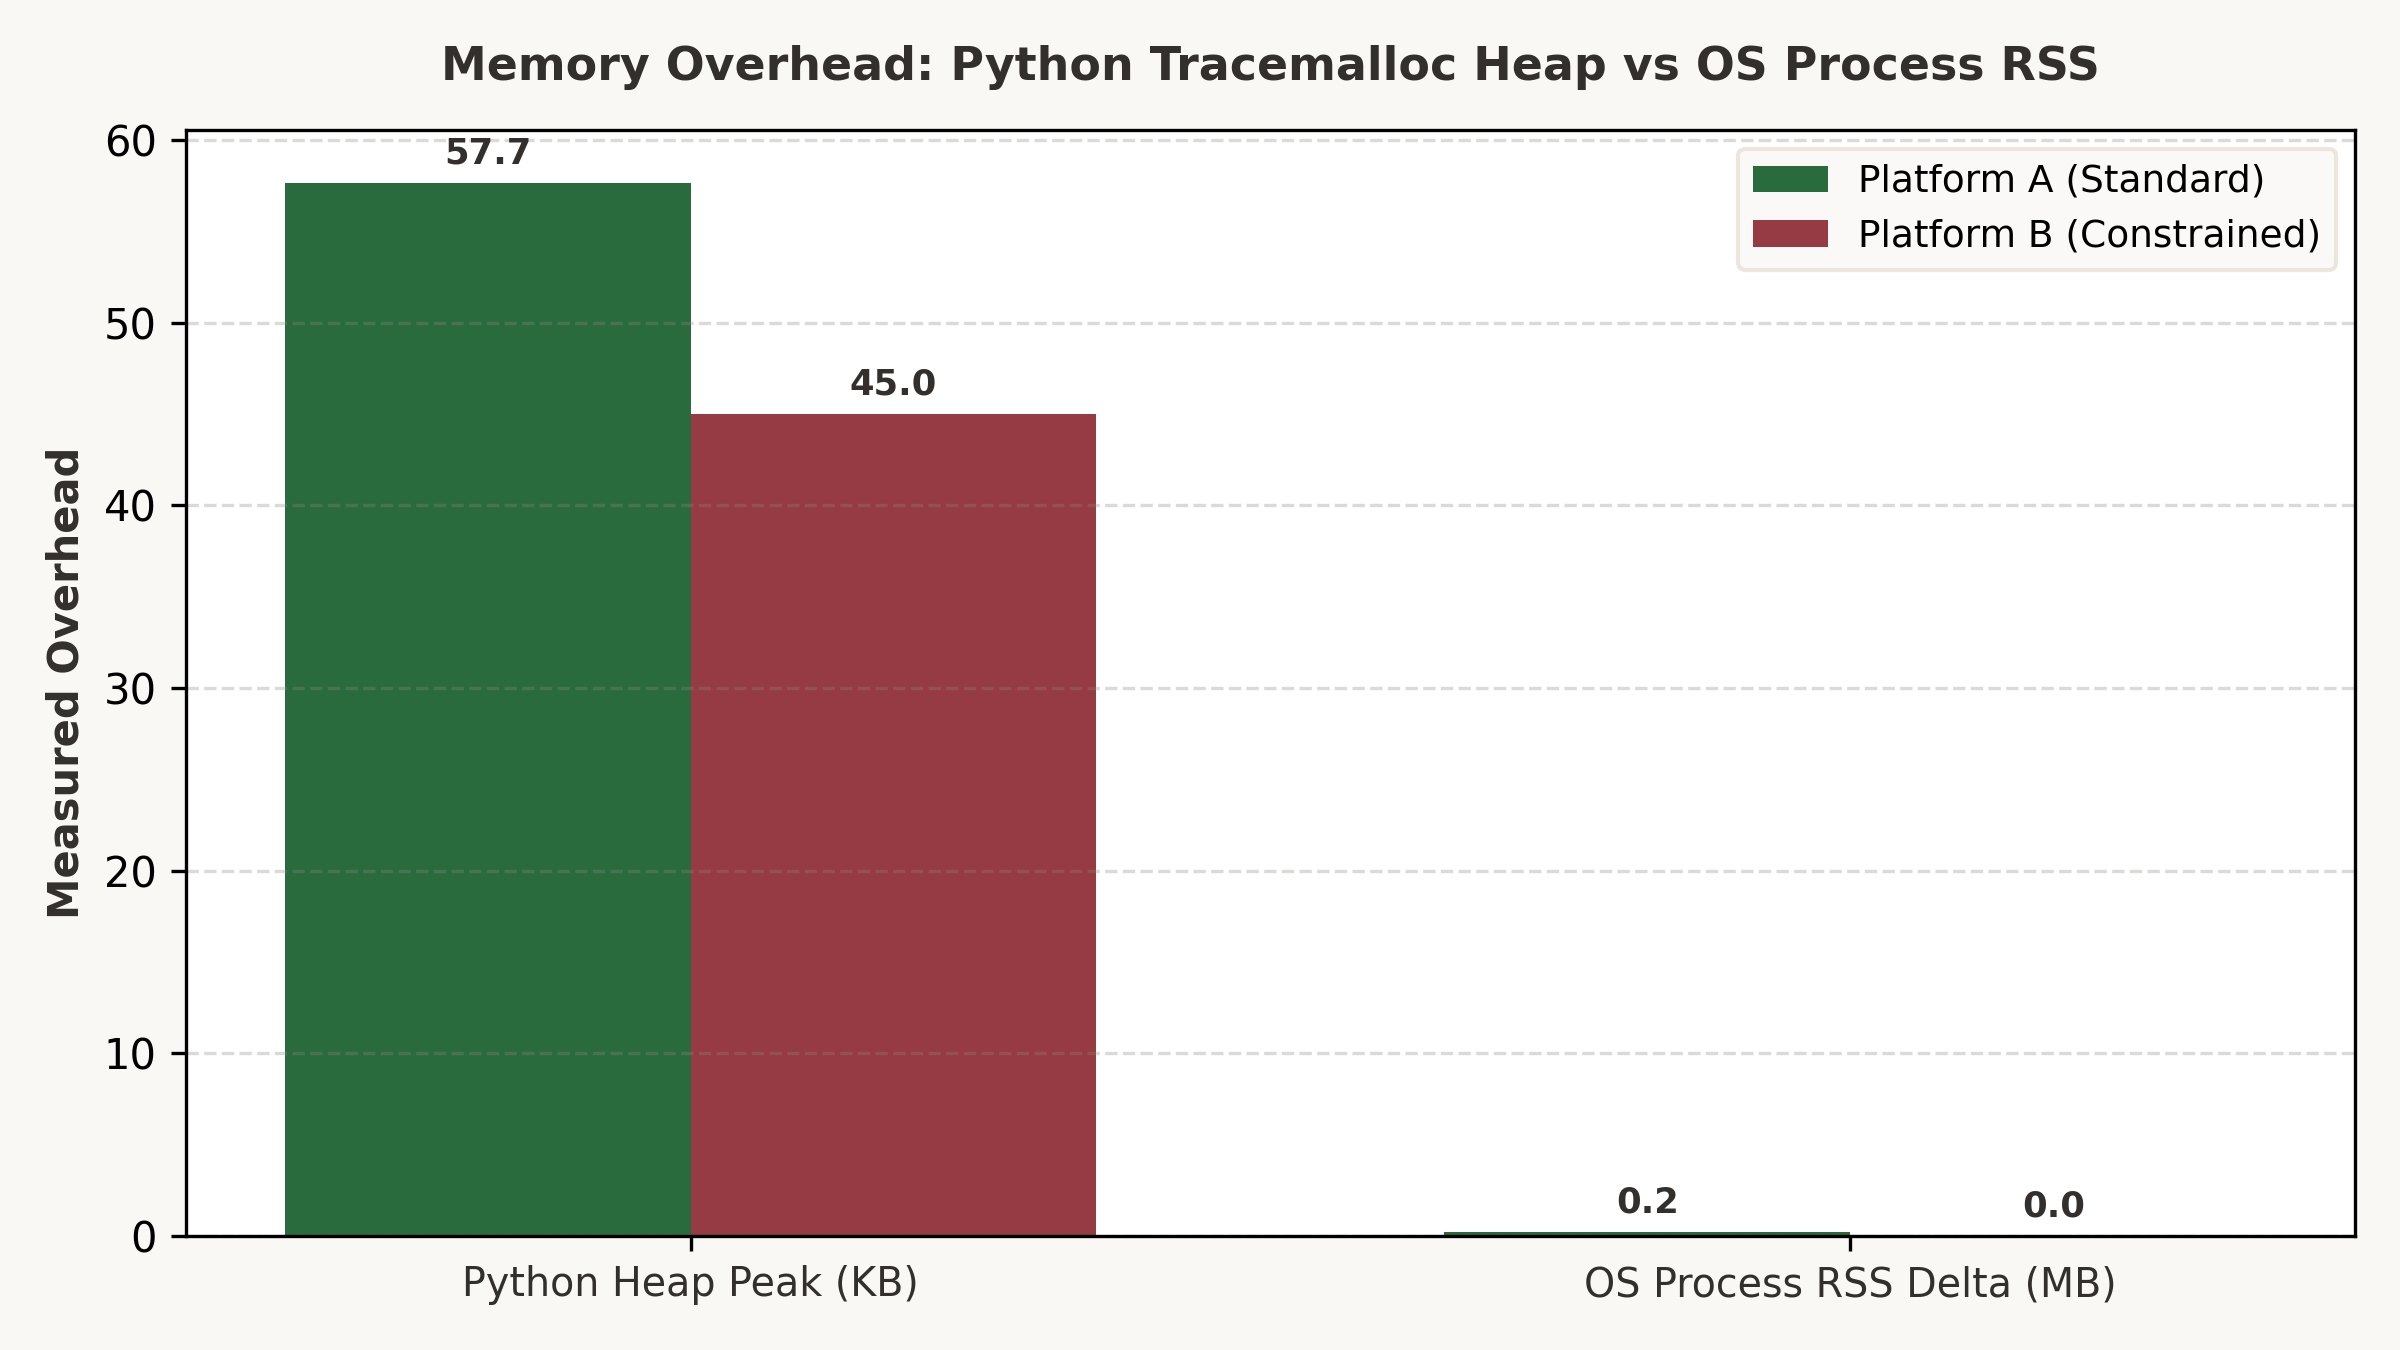

In [8]:
display(Image(filename=fig_mem))

### Figure 4: Processor A vs B Routing & Compilation Comparison

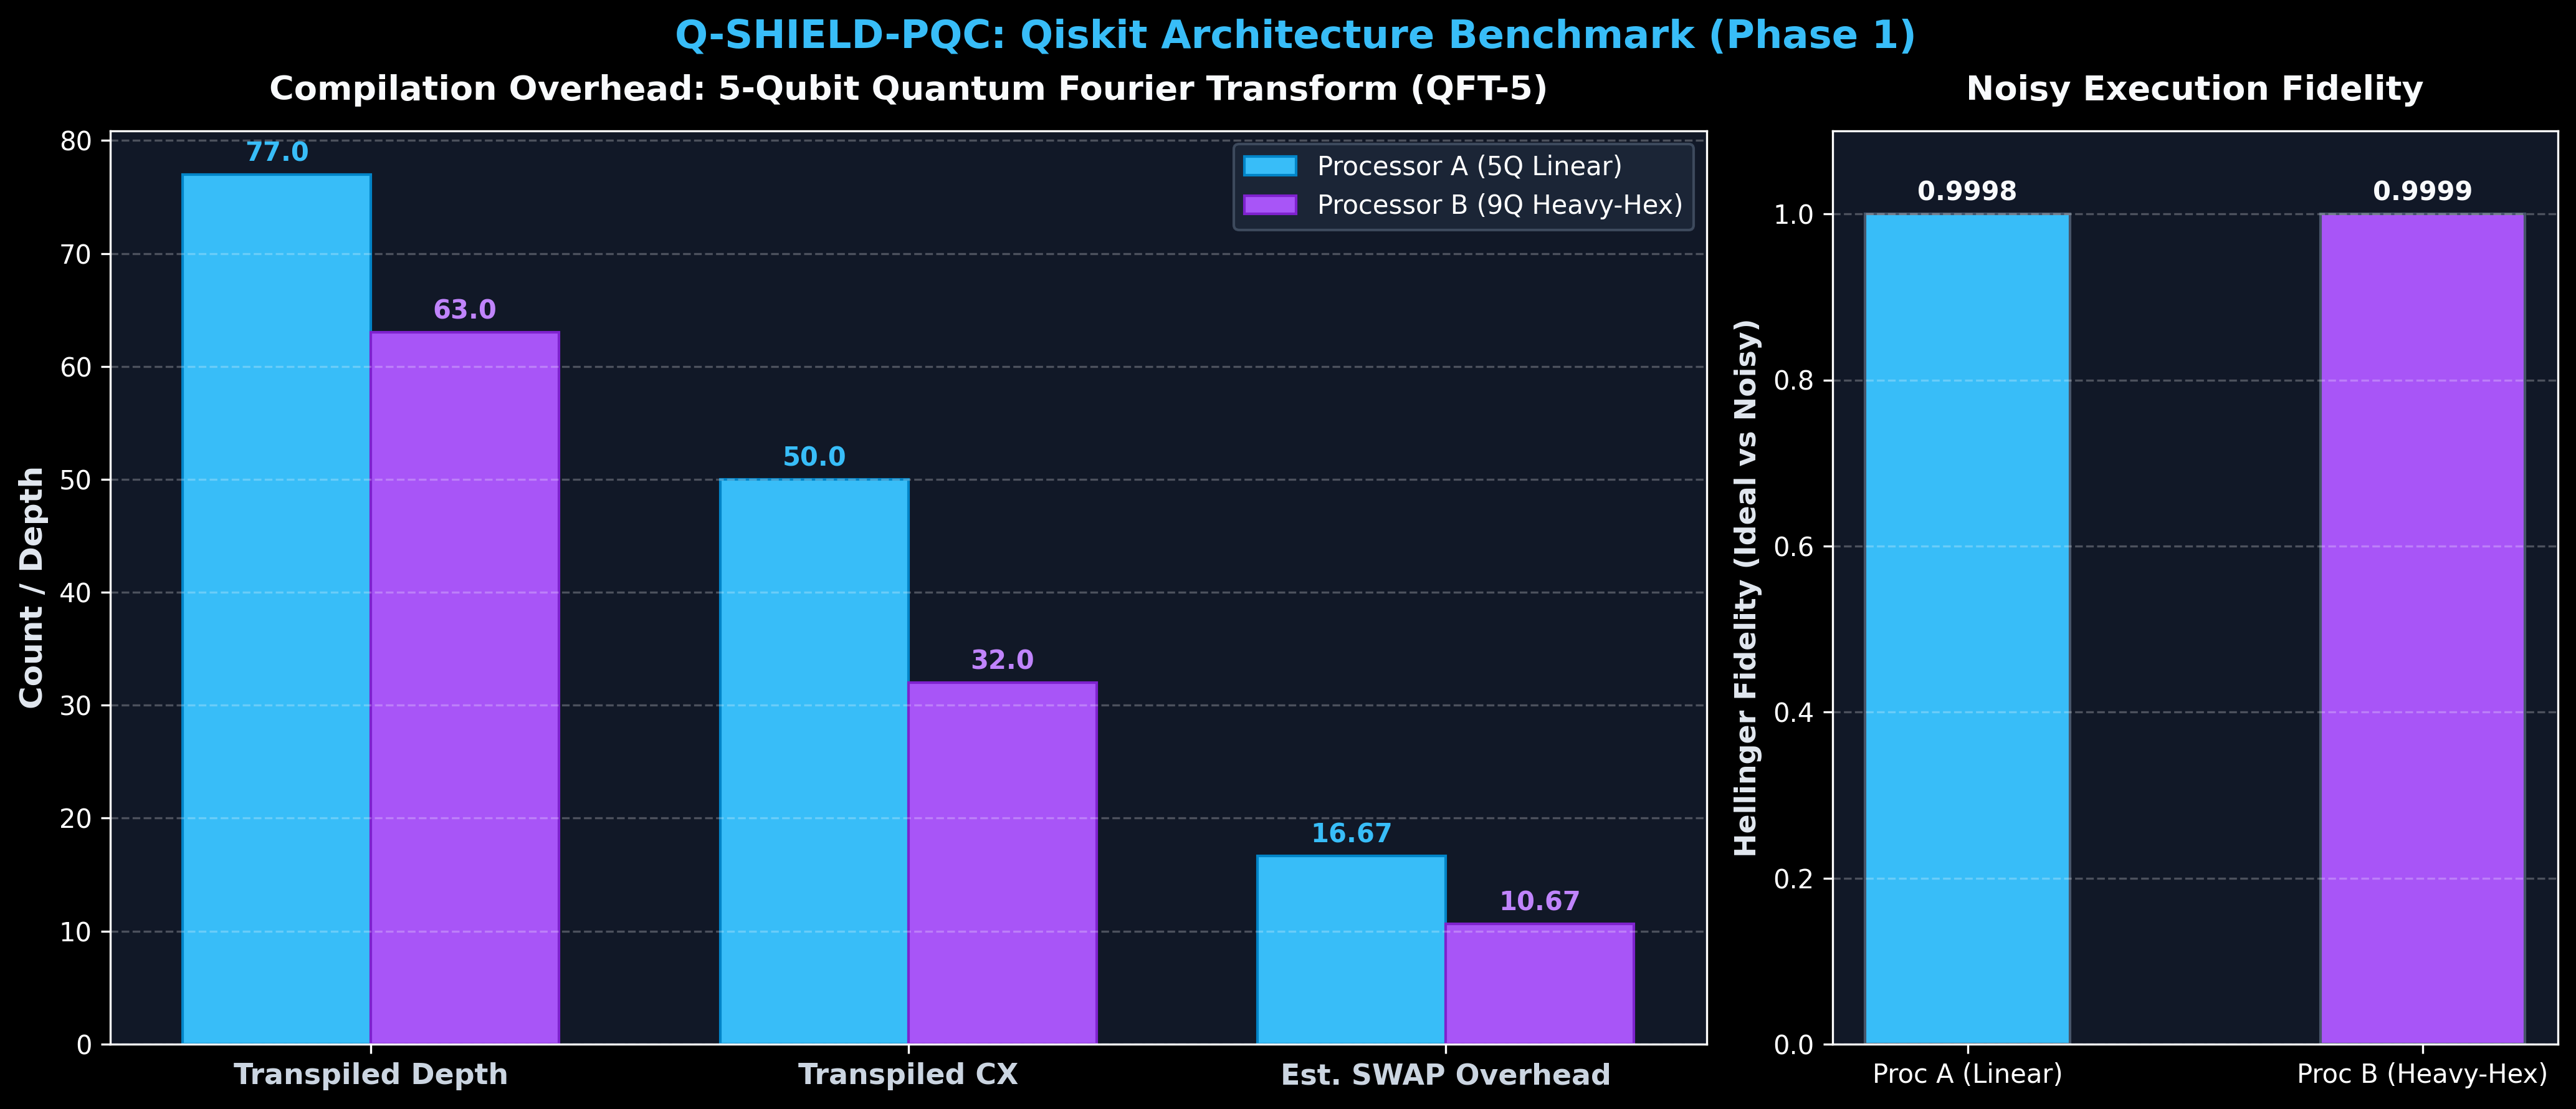

In [9]:
display(Image(filename=fig_proc))

### Figure 5: Universal Reference Topologies (Linear 5Q vs Heavy-Hex 9Q)

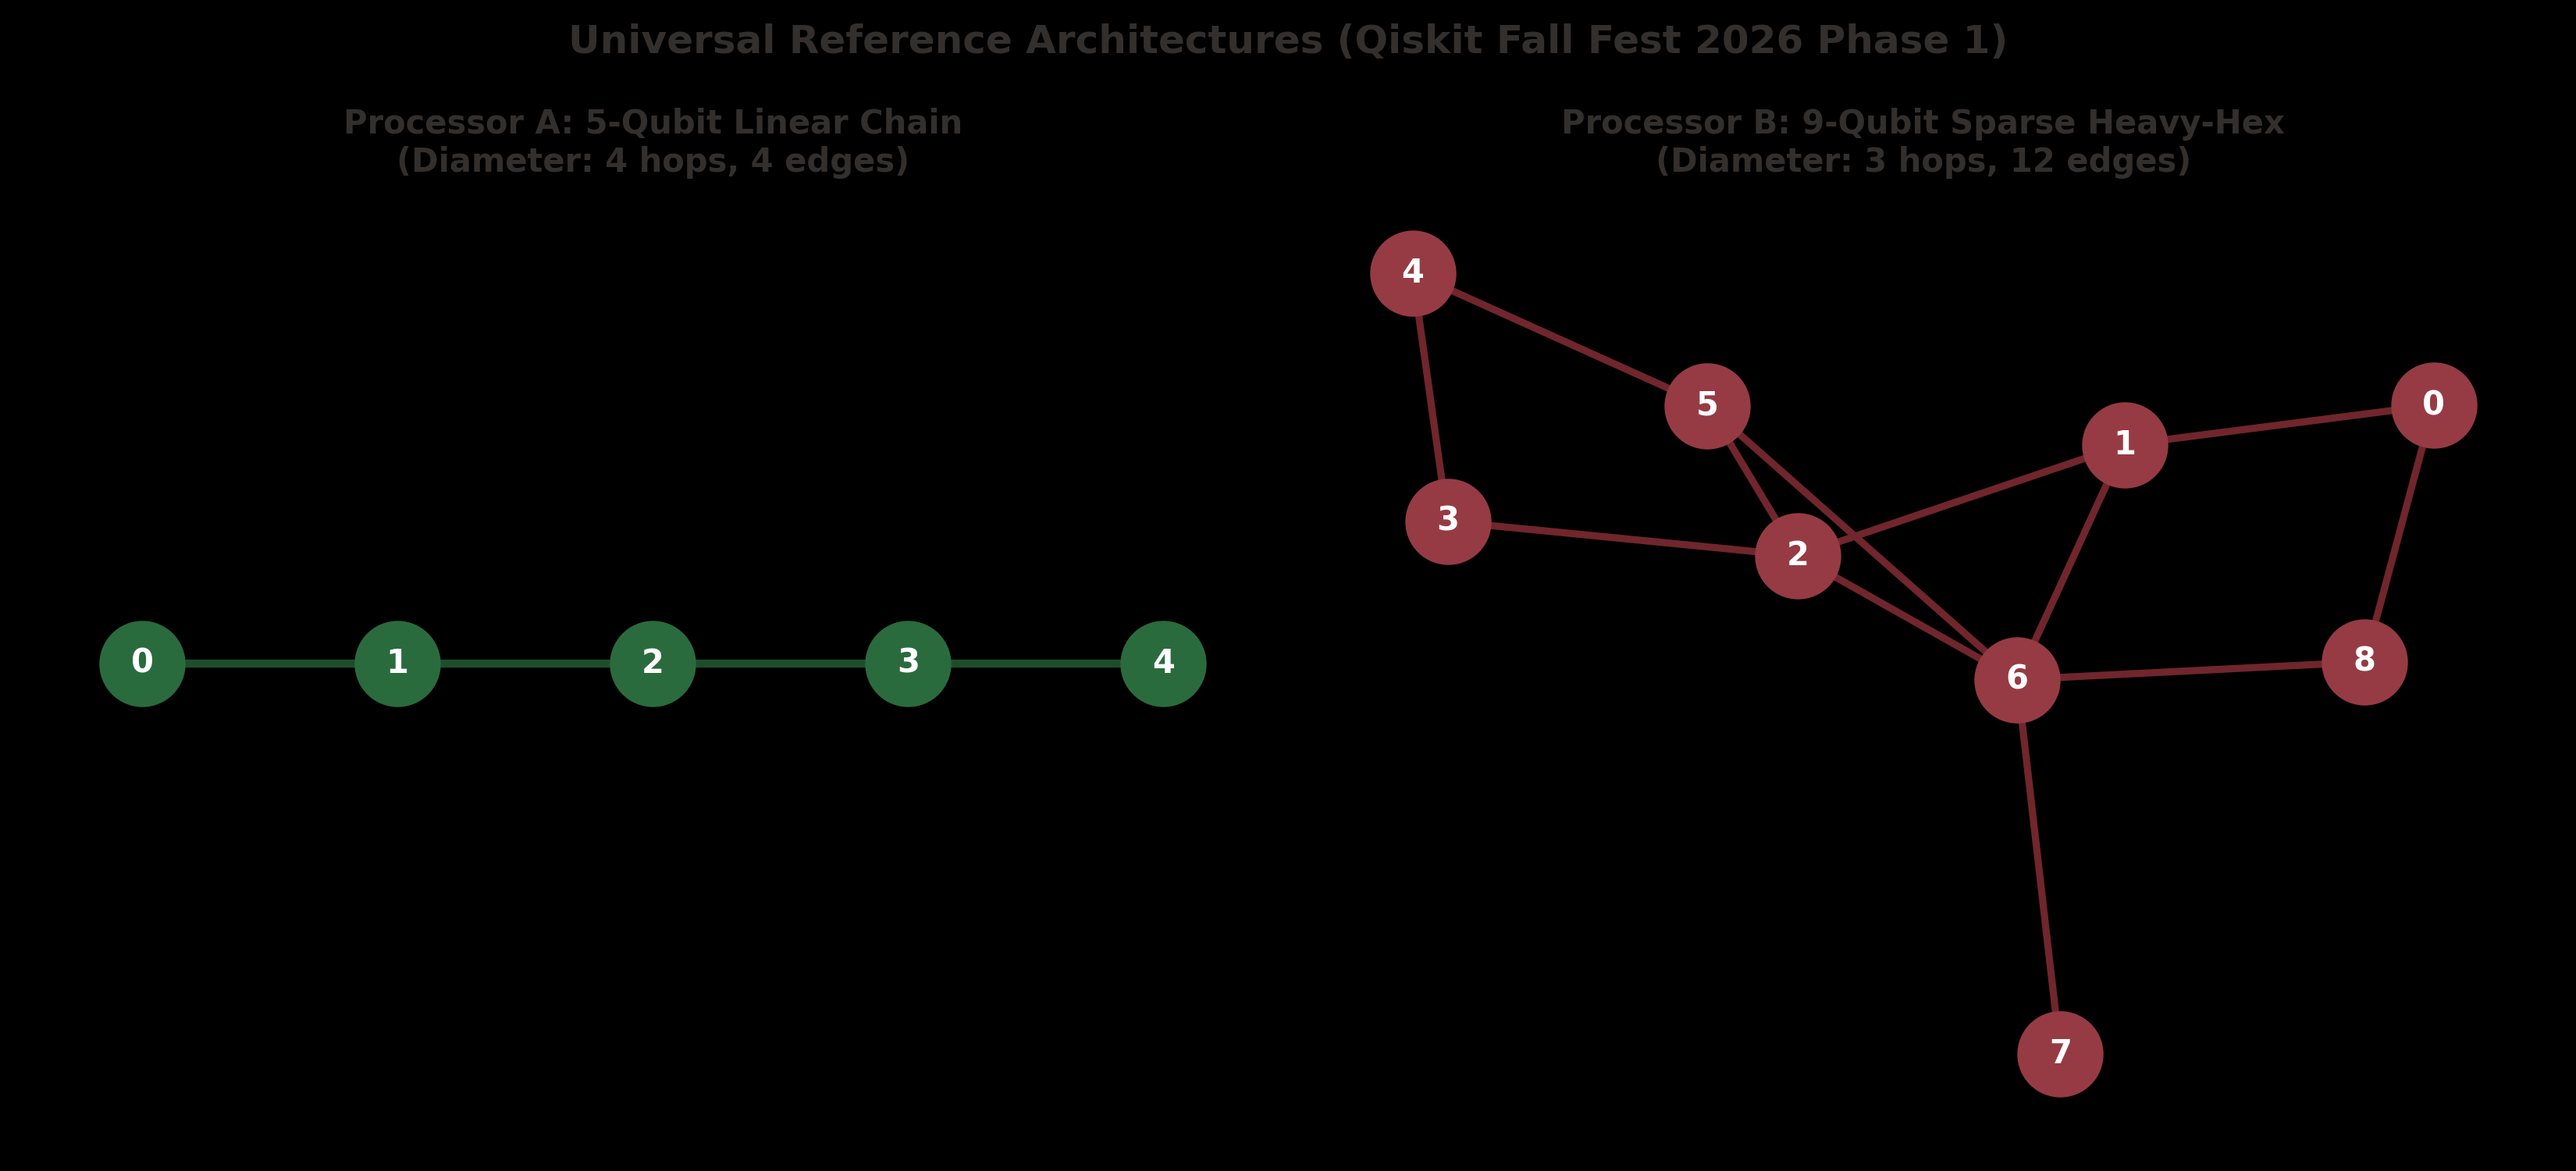

In [10]:
display(Image(filename=fig_topos))

## 5. Summary Tables Audit

In [11]:
summary_csv = Path("results/tables/crypto_benchmark_summary.csv")
if summary_csv.exists():
    df_summary = pd.read_csv(summary_csv)
    display(df_summary)

proc_csv = Path("results/tables/processor_ab_results.csv")
if proc_csv.exists():
    df_proc = pd.read_csv(proc_csv)
    display(df_proc)


,operation,mean_ms,std_dev_ms,median_ms,min_ms,max_ms,p50_ms,p95_ms,p99_ms,sample_count
0,ecdh_keygen,0.1025,0.0319,0.1092,0.0573,0.1809,0.1092,0.1381,0.1640,50
1,ecdh_keygen_ms,0.1025,0.0319,0.1092,0.0573,0.1809,0.1092,0.1381,0.1640,50
2,mlkem_keygen,0.4949,0.1353,0.5370,0.3318,0.8955,0.5370,0.6763,0.8516,50
3,mlkem_keygen_ms,0.4949,0.1353,0.5370,0.3318,0.8955,0.5370,0.6763,0.8516,50
4,ecdh_derivation,0.1956,0.0449,0.2172,0.1404,0.3474,0.2172,0.2432,0.3006,50
5,ecdh_derivation_ms,0.1956,0.0449,0.2172,0.1404,0.3474,0.2172,0.2432,0.3006,50
6,mlkem_encapsulation,0.2018,0.0747,0.2205,0.1238,0.4546,0.2205,0.3172,0.4467,50
7,mlkem_encap_ms,0.2018,0.0747,0.2205,0.1238,0.4546,0.2205,0.3172,0.4467,50
8,mlkem_decapsulation,0.1614,0.0488,0.1742,0.1150,0.4113,0.1742,0.1976,0.3070,50
9,mlkem_decap_ms,0.1614,0.0488,0.1742,0.1150,0.4113,0.1742,0.1976,0.3070,50


,processor,topology,circuit_id,logical_depth,transpiled_depth,logical_cx,transpiled_cx,cx_overhead,swap_estimate,hellinger_fidelity,tvd,shots,edges_count,timestamp
0,Processor A,Linear Chain (5Q),qft_5,17,77,0,50,50,16.67,0.9998,0.0112,4096,4,2026-10-14T15:51:43.053034Z
1,Processor B,Sparse Heavy-Hex (9Q),qft_5,17,63,0,32,32,10.67,0.9999,0.0088,4096,12,2026-10-14T15:51:43.053034Z
